In [6]:
import pandas as pd
from src.io_utils import load_data, coerce_numeric

df = coerce_numeric(load_data("data/library_loans.csv"))
df = df.dropna(subset=["loan_days"]).copy()
df = df[df["loan_days"] > 0].copy()

df["month"] = df["checkout_date"].dt.to_period("M").dt.to_timestamp()
df["week"] = df["checkout_date"].dt.to_period("W").dt.start_time

df.info()
df.head()

<class 'pandas.DataFrame'>
Index: 124 entries, 0 to 127
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   loan_id           124 non-null    str           
 1   checkout_date     124 non-null    datetime64[us]
 2   branch            121 non-null    str           
 3   genre             118 non-null    str           
 4   item_type         123 non-null    str           
 5   patron_age_group  123 non-null    str           
 6   loan_days         124 non-null    int64         
 7   returned_date     108 non-null    datetime64[us]
 8   overdue_days      114 non-null    float64       
 9   fine_amount       113 non-null    float64       
 10  month             124 non-null    datetime64[us]
 11  week              124 non-null    datetime64[us]
dtypes: datetime64[us](4), float64(2), int64(1), str(5)
memory usage: 12.6 KB


,loan_id,checkout_date,branch,genre,item_type,patron_age_group,loan_days,returned_date,overdue_days,fine_amount,month,week
0,L0005,2025-08-05,Väster,Romantik,E-bok,Vuxen,18,2025-08-23,0.0,NaN,2025-08-01,2025-08-04
1,L0041,2025-08-30,Öster,Biografi,Tidskrift,Vuxen,23,2025-09-22,1.0,2.935475,2025-08-01,2025-08-25
2,L0091,2025-03-19,Väster,Biografi,E-bok,Vuxen,23,2025-04-11,2.0,13.479296,2025-03-01,2025-03-17
3,L0083,2025-06-12,Öster,Fakta,Tidskrift,Vuxen,21,2025-07-03,0.0,0.000000,2025-06-01,2025-06-09
4,L0043,2025-08-09,Söder,Biografi,Ljudbok,Vuxen,23,2025-09-01,1.0,6.428793,2025-08-01,2025-08-04


In [7]:
from src import metrics as M

print("Totalt antal lån:", M.total_loans(df))
print("Genomsnittlig lånetid (dagar):",f"{M.avg_loan_days(df):.1f}")
print("Andel övertid (%):", f"{100 * M.overdue_rate(df):.1f}%")
      


Totalt antal lån: 116
Genomsnittlig lånetid (dagar): 21.3
Andel övertid (%): 47.6%


In [8]:
by_genre = M.loans_by_genre(df)
by_branch = M.loans_by_branch(df)
print(by_genre)
print(by_branch)   

      genre  loans
0  Biografi     22
1     Fakta     22
2   Deckare     20
3    Sci-Fi     17
4  Romantik     17
5      Barn     16
6       NaN      6
    branch  loans
0    Öster     32
1   Väster     28
2     Norr     21
3  Centrum     20
4    Söder     13
5      NaN      3


In [9]:
ts_month = M.loans_over_time(df, freq = "ME")
ts_month.head()

,checkout_date,loans
0,2025-01-31,16
1,2025-02-28,15
2,2025-03-31,9
3,2025-04-30,9
4,2025-05-31,13


<Axes: title={'center': 'Lånetid - spridning'}, xlabel='Dagar'>

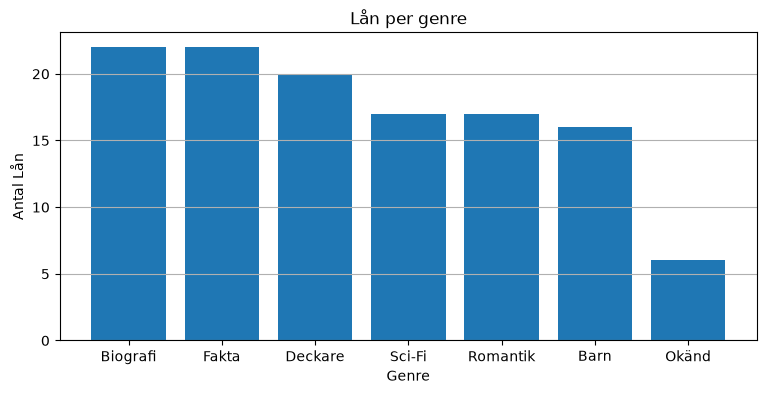

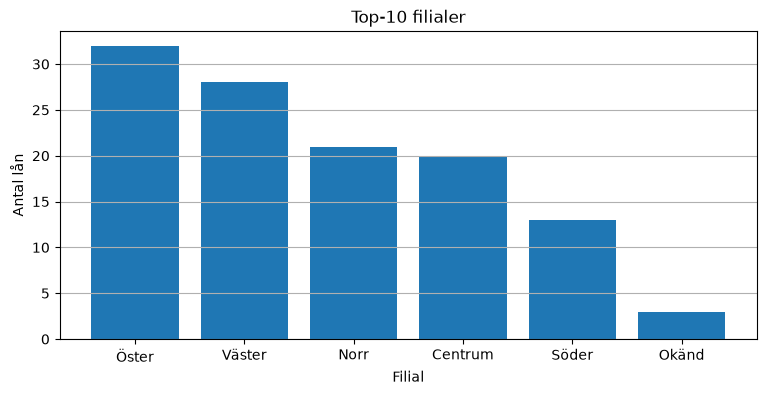

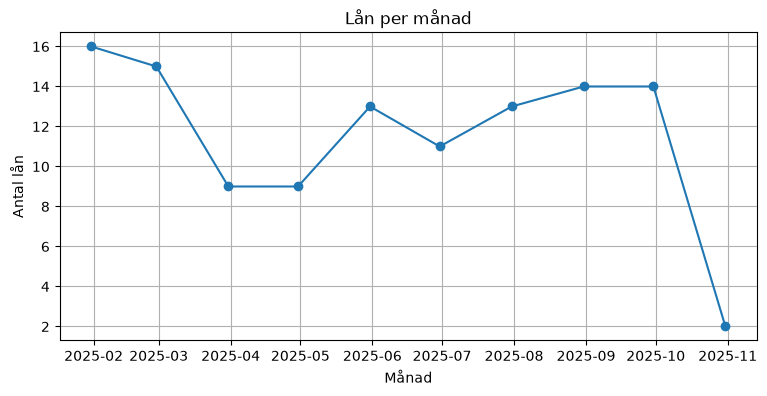

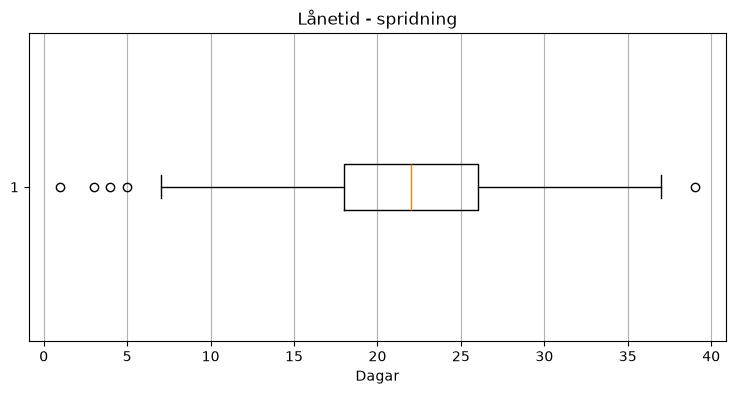

In [10]:
import matplotlib.pyplot as plt
from src import viz as V

#Lån per genre
fig, ax = plt.subplots(figsize=(9,4))
V.bar(ax, by_genre["genre"], by_genre["loans"], "Lån per genre", "Genre", "Antal Lån")

#Top 10 filialer
fig, ax = plt.subplots(figsize = (9,4))
top_10 =by_branch.head(10)
V.bar(ax, top_10["branch"], top_10["loans"], "Top-10 filialer", "Filial", "Antal lån")

#Lån per månad
fig,ax = plt.subplots(figsize = (9,4))
V.line(ax,ts_month["checkout_date"], ts_month["loans"], "Lån per månad", "Månad", "Antal lån")

#Spridning av lånetid
fig,ax = plt.subplots(figsize = (9,4))
V.box_h(ax, df["loan_days"], "Lånetid - spridning", "Dagar")